In [ ]:
import os
import time
import shutil
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_directml
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
import torchvision.models as models

In [2]:

DATA_DIR = Path("isic_data")

if not DATA_DIR.exists():
    print(f"Pasta não encontrada: {DATA_DIR.resolve()}")
else:
    files = [p for p in DATA_DIR.rglob("*") if p.is_file()]
    print(f"Arquivos encontrados: {len(files)}")

    print("\nTipos de arquivo:")
    for ext, count in Counter(p.suffix.lower() or "[sem extensão]" for p in files).most_common():
        print(f"  {ext}: {count}")

    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    images = [p for p in files if p.suffix.lower() in image_exts]
    dimensions = Counter()
    unreadable = []

    for path in images:
        try:
            with Image.open(path) as image:
                dimensions[image.size] += 1
        except Exception:
            unreadable.append(path)

    print(f"\nImagens encontradas: {len(images)}")
    print("Dimensões mais frequentes:")
    for size, count in dimensions.most_common(10):
        print(f"  {size}: {count}")

    if unreadable:
        print(f"Imagens que não puderam ser abertas: {len(unreadable)}")

    csv_files = [p for p in files if p.suffix.lower() == ".csv"]
    print(f"\nArquivos CSV encontrados: {len(csv_files)}")

    for path in csv_files:
        print(f"\n--- {path.relative_to(DATA_DIR)} ---")
        try:
            df = pd.read_csv(path)
            print(f"Linhas: {len(df)} | Colunas: {len(df.columns)}")
            display(df.head())
        except Exception as exc:
            print(f"Não foi possível ler o CSV: {exc}")

Arquivos encontrados: 25335

Tipos de arquivo:
  .jpg: 25331
  .csv: 2
  .txt: 2

Imagens encontradas: 25331
Dimensões mais frequentes:
  (1024, 1024): 12414
  (600, 450): 10015
  (1024, 680): 1121
  (1024, 768): 774
  (1024, 682): 173
  (1024, 685): 156
  (1024, 764): 81
  (1024, 681): 78
  (767, 576): 68
  (1024, 679): 68

Arquivos CSV encontrados: 2

--- ISIC_2019_Training_GroundTruth.csv ---
Linhas: 25331 | Colunas: 10


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



--- ISIC_2019_Training_Metadata.csv ---
Linhas: 25331 | Colunas: 5


,image,age_approx,anatom_site_general,lesion_id,sex
0,ISIC_0000000,55.0,anterior torso,NaN,female
1,ISIC_0000001,30.0,anterior torso,NaN,female
2,ISIC_0000002,60.0,upper extremity,NaN,female
3,ISIC_0000003,30.0,upper extremity,NaN,male
4,ISIC_0000004,80.0,posterior torso,NaN,male


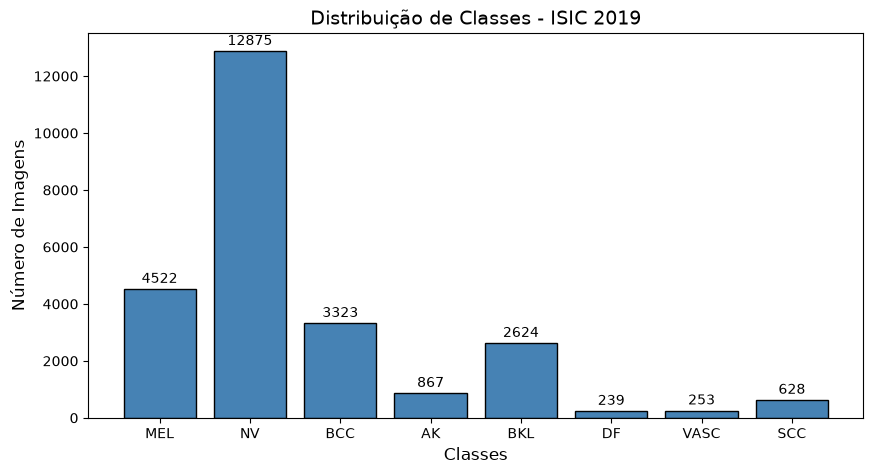


Pesos calculados para cada classe:
MEL: 0.7002
NV: 0.2459
BCC: 0.9529
AK: 3.6521
BKL: 1.2067
DF: 13.2484
VASC: 12.5153
SCC: 5.0420


In [3]:
# 1. Carregar o arquivo de Ground Truth
df_gt = pd.read_csv(r'C:\Users\Junior\Desktop\classifica-lesao\v3\isic_data\ISIC_2019_Training_GroundTruth.csv')

# Extrair os nomes das classes (ignorando a coluna 'image')
class_names = [name for name in df_gt.columns[1:] if name != 'UNK']

# Somar as ocorrências de cada classe
class_counts = df_gt[class_names].sum()

# 2. Plotar a distribuição para visualização
plt.figure(figsize=(10, 5))
bars = plt.bar(class_names, class_counts, color='steelblue', edgecolor='black')
plt.title('Distribuição de Classes - ISIC 2019', fontsize=14)
plt.ylabel('Número de Imagens', fontsize=12)
plt.xlabel('Classes', fontsize=12)

# Adicionar os valores exatos em cima de cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 100, int(yval), ha='center', va='bottom', fontsize=10)

plt.show()

# 3. Calcular os Pesos das Classes
total_samples = class_counts.sum()
num_classes = len(class_names)

# Fórmula heurística recomendada pelo scikit-learn (balanced)
# Peso = Total de Amostras / (Número de Classes * Amostras da Classe)
weights = total_samples / (num_classes * class_counts)

print("\nPesos calculados para cada classe:")
for name, weight in zip(class_names, weights):
    print(f"{name}: {weight:.4f}")

# Converter para Tensor do PyTorch (tipo float32 é obrigatório para a Loss)
class_weights_tensor = torch.tensor(weights.values, dtype=torch.float32)

In [4]:
# Ajuste os nomes das pastas conforme a sua estrutura atual
pasta_original = r'C:\Users\Junior\Desktop\classifica-lesao\v3\isic_data' 
pasta_backup = f'{pasta_original}-backup'

if not os.path.exists(pasta_backup):
    print(f"Iniciando a cópia de '{pasta_original}' para '{pasta_backup}'...")
    shutil.copytree(pasta_original, pasta_backup)
    print("Backup concluído com sucesso! ✅")
else:
    print(f"A pasta '{pasta_backup}' já existe. Cópia ignorada.")

A pasta 'C:\Users\Junior\Desktop\classifica-lesao\v3\isic_data-backup' já existe. Cópia ignorada.


In [ ]:
# 1. Configurar os caminhos para a pasta de backup
BACKUP_DIR = r'C:\Users\Junior\Desktop\classifica-lesao\v3\isic_data-backup' 
CSV_PATH = os.path.join(BACKUP_DIR, 'ISIC_2019_Training_GroundTruth.csv')

# As imagens estão dentro da pasta de entrada do ISIC.
IMG_DIR = os.path.join(BACKUP_DIR, 'ISIC_2019_Training_Input', 'ISIC_2019_Training_Input')

class ISICDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        
        # Ler o CSV do backup
        self.df = pd.read_csv(csv_file)
        
        # Remover a classe UNK para mantermos apenas as 8 classes
        if 'UNK' in self.df.columns:
            self.df = self.df.drop(columns=['UNK'])
            
        self.class_names = self.df.columns[1:]
        
        # Nomes das imagens
        self.image_names = self.df['image'].values
        
        # Rótulos: Converter de one-hot para índice (0 a 7)
        labels_one_hot = self.df[self.class_names].values
        self.labels = np.argmax(labels_one_hot, axis=1)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # O CSV não tem a extensão, então adicionamos '.jpg'
        img_name = f"{self.image_names[idx]}.jpg"
        img_path = os.path.join(self.img_dir, img_name)
        
        image = Image.open(img_path).convert("RGB")
        
        if self.transform:
            image = self.transform(image)
            
        # A CrossEntropyLoss exige que os rótulos sejam do tipo 'long' (int64)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        
        return image, label

# 2. Definir transformações (Resize e Normalização padrão da ImageNet)
transformacoes = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Instanciar o Dataset e DataLoader
dataset = ISICDataset(csv_file=CSV_PATH, img_dir=IMG_DIR, transform=transformacoes)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=0)

print(f"Dataset carregado com {len(dataset)} imagens.")

Dataset carregado com 25331 imagens.


In [6]:
# Calcular a frequência das 8 classes
class_counts = dataset.df[dataset.class_names].sum()
total_samples = class_counts.sum()
num_classes = len(dataset.class_names)

# Calcular os pesos: Total / (Num_Classes * Amostras_da_Classe)
weights = total_samples / (num_classes * class_counts)

# Selecionar explicitamente a GPU AMD via DirectML (sem fallback para CUDA/CPU)
if torch_directml.device_count() < 1:
    raise RuntimeError('Nenhuma GPU compatível foi encontrada pelo DirectML.')

device = torch_directml.device(0)
gpu_name = torch_directml.device_name(0).rstrip('\x00').strip()
if 'AMD' not in gpu_name.upper():
    raise RuntimeError(f'O adaptador DirectML selecionado não parece ser AMD: {gpu_name}')

class_weights_tensor = torch.tensor(weights.values, dtype=torch.float32).to(device)

print(f'Treinamento configurado para GPU AMD: {gpu_name} ({device})')
print("\nPesos aplicados na Loss Function (8 classes):")
for name, weight in zip(dataset.class_names, weights):
    print(f"{name}: {weight:.4f}")

# Instanciar a função de perda com os pesos
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

Treinamento configurado para GPU AMD: AMD Radeon RX 7600 (privateuseone:0)

Pesos aplicados na Loss Function (8 classes):
MEL: 0.7002
NV: 0.2459
BCC: 0.9529
AK: 3.6521
BKL: 1.2067
DF: 13.2484
VASC: 12.5153
SCC: 5.0420


In [ ]:
# 1. Recarregar o modelo e os pesos
model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.DEFAULT)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 8)

# 2. Enviar o modelo e os pesos da Loss para a placa AMD
model = model.to(device)
assert next(model.parameters()).device == device, 'O modelo não foi enviado para a GPU AMD.'
class_weights_tensor = class_weights_tensor.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Learning Rate Scheduler para reduzir a taxa gradativamente
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

In [9]:
from torch.utils.data import DataLoader, Subset

# Divisão estratificada e reprodutível para manter todas as classes na validação.
SEED = 42
VAL_FRACTION = 0.20
labels = np.asarray(dataset.labels)
rng = np.random.default_rng(SEED)
train_indices = []
val_indices = []

for class_idx in range(len(dataset.class_names)):
    class_indices = np.flatnonzero(labels == class_idx)
    rng.shuffle(class_indices)
    n_val = max(1, int(round(len(class_indices) * VAL_FRACTION)))
    val_indices.extend(class_indices[:n_val].tolist())
    train_indices.extend(class_indices[n_val:].tolist())

rng.shuffle(train_indices)
rng.shuffle(val_indices)

# Aumentações geométricas leves só no treino; validação permanece sem aleatoriedade.
transform_treino = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
dataset_treino = ISICDataset(csv_file=CSV_PATH, img_dir=IMG_DIR, transform=transform_treino)
train_dataset = Subset(dataset_treino, train_indices)
val_dataset = Subset(dataset, val_indices)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=False)

# Pesos suavizados calculados apenas com o conjunto de treino, evitando sobrepeso extremo.
train_class_counts = np.bincount(labels[train_indices], minlength=len(dataset.class_names))
if np.any(train_class_counts == 0):
    raise ValueError('A divisão de treino deixou uma classe sem amostras.')
class_weights = np.sqrt(train_class_counts.sum() / (len(train_class_counts) * train_class_counts))
class_weights /= class_weights.mean()
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

print(f"Treino: {len(train_dataset)} imagens | Validação: {len(val_dataset)} imagens")
print("Pesos suavizados por classe:")
for name, weight in zip(dataset.class_names, class_weights):
    print(f"{name}: {weight:.3f}")

Treino: 20264 imagens | Validação: 5067 imagens
Pesos suavizados por classe:
MEL: 0.454
NV: 0.269
BCC: 0.530
AK: 1.036
BKL: 0.596
DF: 1.976
VASC: 1.921
SCC: 1.219


In [10]:
# Seleciona o checkpoint pelo recall macro e interrompe quando ele deixa de melhorar.
NUM_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 4
MIN_RECALL_DELTA = 0.001
best_val_recall = -1.0
best_val_loss = float('inf')
epochs_without_improvement = 0
caminho_modelo = 'isic_efficientnet_melhor.pth'
num_classes = len(dataset.class_names)

print(f"\nIniciando o treinamento por até {NUM_EPOCHS} épocas...")

for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    # --- FASE DE TREINO ---
    model.train()
    train_loss = torch.zeros((), device=device)
    correct_train = torch.zeros((), dtype=torch.long, device=device)
    total_train = 0
    loop_treino = tqdm(train_loader, desc=f"Época {epoch+1}/{NUM_EPOCHS} [Treino]", unit="batch")

    for batch_idx, (images, labels) in enumerate(loop_treino):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.detach() * images.size(0)
        predicted = outputs.argmax(dim=1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum()
        if (batch_idx + 1) % 20 == 0 or batch_idx + 1 == len(loop_treino):
            loop_treino.set_postfix(loss=f"{loss.detach().item():.4f}")

    # --- FASE DE VALIDAÇÃO ---
    model.eval()
    val_loss = torch.zeros((), device=device)
    correct_val = torch.zeros((), dtype=torch.long, device=device)
    total_val = 0
    val_confusion = np.zeros((num_classes, num_classes), dtype=np.int64)
    loop_val = tqdm(val_loader, desc=f"Época {epoch+1}/{NUM_EPOCHS} [Validação]", unit="batch")

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(loop_val):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.detach() * images.size(0)
            predicted = outputs.argmax(dim=1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum()
            true_cpu = labels.detach().cpu().numpy()
            predicted_cpu = predicted.detach().cpu().numpy()
            np.add.at(val_confusion, (true_cpu, predicted_cpu), 1)
            if (batch_idx + 1) % 20 == 0 or batch_idx + 1 == len(loop_val):
                loop_val.set_postfix(loss=f"{loss.detach().item():.4f}")

    # Recall macro dá o mesmo peso a cada classe, inclusive às minoritárias.
    epoch_train_loss = train_loss.item() / total_train
    epoch_train_acc = correct_train.item() / total_train
    epoch_val_loss = val_loss.item() / total_val
    epoch_val_acc = correct_val.item() / total_val
    class_support = val_confusion.sum(axis=1)
    class_recall = np.divide(
        np.diag(val_confusion), class_support,
        out=np.zeros(num_classes, dtype=float), where=class_support > 0
    )
    epoch_val_recall = float(class_recall.mean())
    scheduler.step(epoch_val_loss)
    elapsed_time = time.time() - start_time

    print(f"\n--- Resumo Época {epoch+1} ({elapsed_time:.0f} segundos) ---")
    print(f"Treino - Loss: {epoch_train_loss:.4f}, Acurácia: {epoch_train_acc*100:.2f}%")
    print(f"Validação - Loss: {epoch_val_loss:.4f}, Acurácia: {epoch_val_acc*100:.2f}%, Recall macro: {epoch_val_recall*100:.2f}%")
    for name, recall in zip(dataset.class_names, class_recall):
        print(f"  Recall {name}: {recall*100:.2f}%")

    improved_recall = epoch_val_recall > best_val_recall + MIN_RECALL_DELTA
    tied_recall_better_loss = abs(epoch_val_recall - best_val_recall) <= MIN_RECALL_DELTA and epoch_val_loss < best_val_loss
    if improved_recall or tied_recall_better_loss:
        best_val_recall = epoch_val_recall
        best_val_loss = epoch_val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), caminho_modelo)
        print(f"🌟 Melhor checkpoint salvo (Recall macro: {best_val_recall*100:.2f}%)\n")
    else:
        epochs_without_improvement += 1
        print(f"Sem melhora no recall macro: {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}\n")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Parada antecipada para reduzir sobreajuste.")
        break

# Deixa em memória o checkpoint escolhido pela validação.
model.load_state_dict(torch.load(caminho_modelo, map_location='cpu'))


Iniciando o treinamento por até 10 épocas...


Época 1/10 [Treino]:   0%|          | 0/634 [00:00<?, ?batch/s]c:\Users\Junior\Desktop\classifica-lesao\.venv\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)
Época 1/10 [Validação]: 100%|██████████| 159/159 [01:22<00:00,  1.92batch/s, loss=1.4080]



--- Resumo Época 1 (3398 segundos) ---
Treino - Loss: 1.2614, Acurácia: 64.55%
Validação - Loss: 0.9520, Acurácia: 70.93%, Recall macro: 57.22%
  Recall MEL: 60.62%
  Recall NV: 81.01%
  Recall BCC: 81.50%
  Recall AK: 50.87%
  Recall BKL: 45.90%
  Recall DF: 31.25%
  Recall VASC: 80.39%
  Recall SCC: 26.19%
🌟 Melhor checkpoint salvo (Recall macro: 57.22%)



Época 2/10 [Validação]: 100%|██████████| 159/159 [02:08<00:00,  1.23batch/s, loss=1.6951]



--- Resumo Época 2 (3204 segundos) ---
Treino - Loss: 0.8741, Acurácia: 72.68%
Validação - Loss: 0.7774, Acurácia: 75.43%, Recall macro: 67.99%
  Recall MEL: 60.29%
  Recall NV: 87.46%
  Recall BCC: 67.67%
  Recall AK: 57.23%
  Recall BKL: 62.48%
  Recall DF: 64.58%
  Recall VASC: 86.27%
  Recall SCC: 57.94%
🌟 Melhor checkpoint salvo (Recall macro: 67.99%)



...

Época 9/10 [Validação]: 100%|██████████| 159/159 [02:36<00:00,  1.02batch/s, loss=1.4928]



--- Resumo Época 9 (2225 segundos) ---
Treino - Loss: 0.2800, Acurácia: 89.85%
Validação - Loss: 0.5754, Acurácia: 83.40%, Recall macro: 80.53%
  Recall MEL: 78.76%
  Recall NV: 88.35%
  Recall BCC: 80.60%
  Recall AK: 71.68%
  Recall BKL: 76.95%
  Recall DF: 87.50%
  Recall VASC: 92.16%
  Recall SCC: 68.25%
🌟 Melhor checkpoint salvo (Recall macro: 80.53%)



Época 10/10 [Validação]: 100%|██████████| 159/159 [02:50<00:00,  1.07s/batch, loss=1.6414]
C:\Users\Junior\AppData\Local\Temp\ipykernel_25936\4066363904.py:99: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related


--- Resumo Época 10 (2345 segundos) ---
Treino - Loss: 0.2442, Acurácia: 90.82%
Validação - Loss: 0.6193, Acurácia: 84.63%, Recall macro: 79.46%
  Recall MEL: 71.24%
  Recall NV: 94.52%
  Recall BCC: 79.25%
  Recall AK: 71.68%
  Recall BKL: 73.71%
  Recall DF: 83.33%
  Recall VASC: 96.08%
  Recall SCC: 65.87%
Sem melhora no recall macro: 1/4



<All keys matched successfully>

Gerando previsões. Isso pode levar alguns segundos...


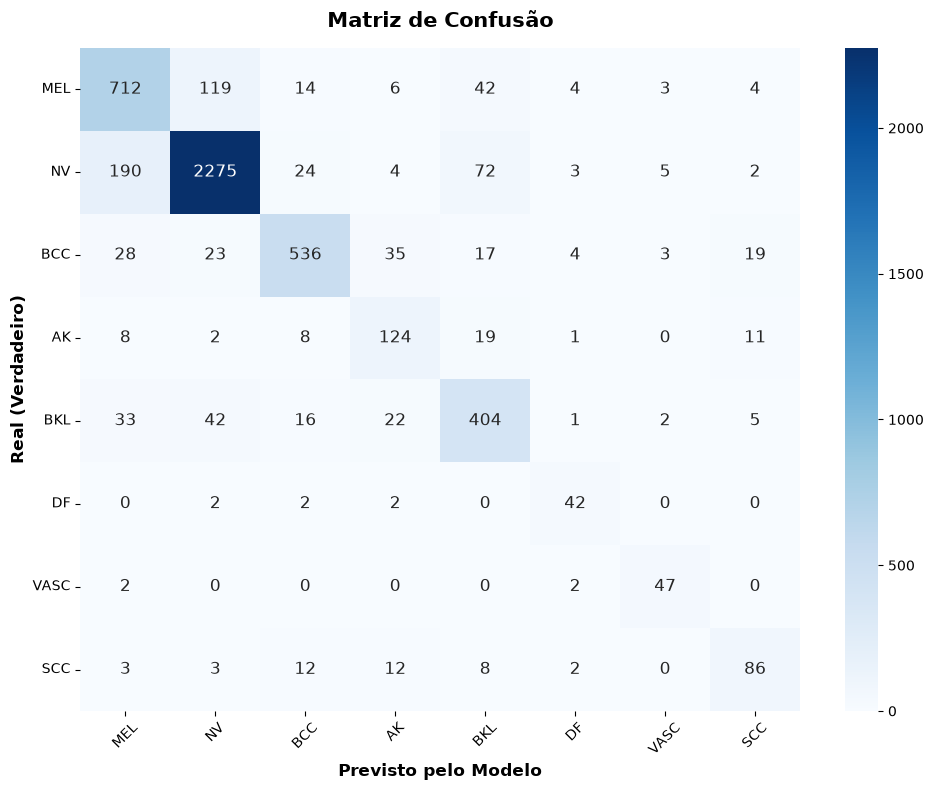

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

model.eval()

todas_previsoes = []
todos_rotulos = []

print("Gerando previsões. Isso pode levar alguns segundos...")

with torch.no_grad(): 
    for images, labels in val_loader:
        images = images.to(device)
        
        outputs = model(images)
        previsoes = outputs.argmax(dim=1)
        
        # Move os resultados de volta para a CPU e guarda na lista
        todas_previsoes.extend(previsoes.cpu().numpy())
        todos_rotulos.extend(labels.numpy())

cm = confusion_matrix(todos_rotulos, todas_previsoes)


class_names = dataset.class_names 

plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 12}) 

plt.xlabel('Previsto pelo Modelo', fontsize=12, fontweight='bold')
plt.ylabel('Real (Verdadeiro)', fontsize=12, fontweight='bold')
plt.title('Matriz de Confusão', fontsize=15, fontweight='bold', pad=15)

plt.xticks(rotation=45) 
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [42]:
# 1. Configurações Iniciais
caminho_modelo = 'isic_efficientnet_melhor.pth'
pasta_teste = 'testar_imagens' # Nome da pasta onde você colocará as fotos
class_names = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Cria a pasta caso ela não exista
if not os.path.exists(pasta_teste):
    os.makedirs(pasta_teste)
    print(f"📁 Pasta '{pasta_teste}' criada com sucesso!")
    print(f"Por favor, coloque algumas imagens de lesões de pele (.jpg ou .png) dentro da pasta '{pasta_teste}' e rode este código novamente.")
else:
    # 2. Carregar o Modelo
    model = models.efficientnet_b3(weights=None) 
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, len(class_names))
    
    model.load_state_dict(torch.load(caminho_modelo, map_location=device, weights_only=False))
    model = model.to(device)
    model.eval() # Modo de avaliação


    transformacao = transforms.Compose([
        transforms.Resize((224, 224)), 
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    # 4. Encontrar imagens na pasta
    imagens_na_pasta = [f for f in os.listdir(pasta_teste) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    if len(imagens_na_pasta) == 0:
        print(f"⚠️ Nenhuma imagem encontrada na pasta '{pasta_teste}'. Adicione algumas fotos e tente de novo.")
    else:
        print(f"🔍 Analisando {len(imagens_na_pasta)} imagem(ns)...\n")
        
        # 5. Fazer previsões
        with torch.no_grad():
            for nome_arquivo in imagens_na_pasta:
                caminho_imagem = os.path.join(pasta_teste, nome_arquivo)
                
                # Abre a imagem e prepara para o modelo
                imagem = Image.open(caminho_imagem).convert('RGB')
                imagem_tensor = transformacao(imagem).unsqueeze(0).to(device) # unsqueeze(0) simula um batch de 1 imagem
                
                # Passa a imagem pelo modelo
                outputs = model(imagem_tensor)
                probabilidades = F.softmax(outputs, dim=1)[0] # Converte para porcentagens (0.0 a 1.0)
                
                # Pega a classe com maior probabilidade
                prob, classe_idx = torch.max(probabilidades, dim=0)
                classe_prevista = class_names[classe_idx.item()]
                porcentagem_principal = prob.item() * 100
                
                print(f"🖼️ Imagem: {nome_arquivo}")
                print(f"   ➔ Diagnóstico Principal: {classe_prevista} ({porcentagem_principal:.2f}% de certeza)")
                
                # Regra do Limiar de 15% para Melanoma
                indice_mel = class_names.index('MEL')
                prob_mel = probabilidades[indice_mel].item() * 100
                
                if classe_prevista != 'MEL' and prob_mel >= 15.0:
                    print(f"   ⚠️ ALERTA MÉDICO: A probabilidade de ser Melanoma (MEL) é {prob_mel:.2f}%.")
                    print(f"      Pela regra de segurança (limiar > 15%), esta lesão deve ser investigada como MEL!")
                
                print("-" * 50)

🔍 Analisando 2 imagem(ns)...

🖼️ Imagem: teste_1.png
   ➔ Diagnóstico Principal: MEL (92.36% de certeza)
--------------------------------------------------
🖼️ Imagem: teste_2.png
   ➔ Diagnóstico Principal: NV (71.62% de certeza)
--------------------------------------------------


Processando imagens de validação. Isso pode levar alguns minutos...

📊 Exibindo Matriz de Confusão BASE (Sem Limiar)...


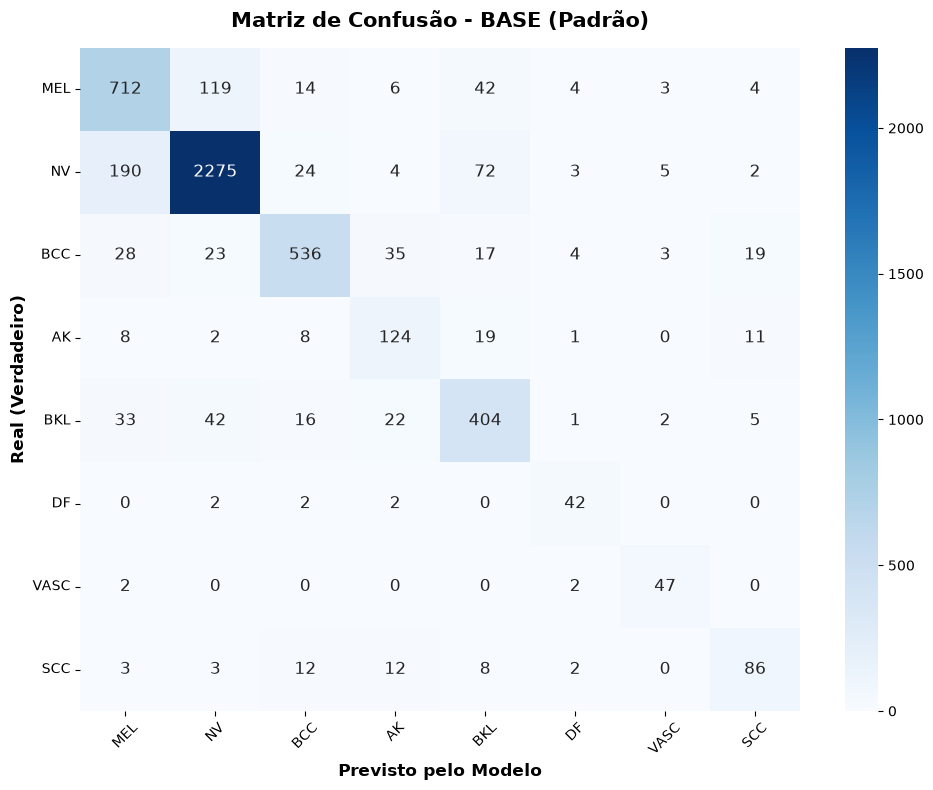


📊 Exibindo Matriz de Confusão AJUSTADA (Limiar 15% para MEL)...


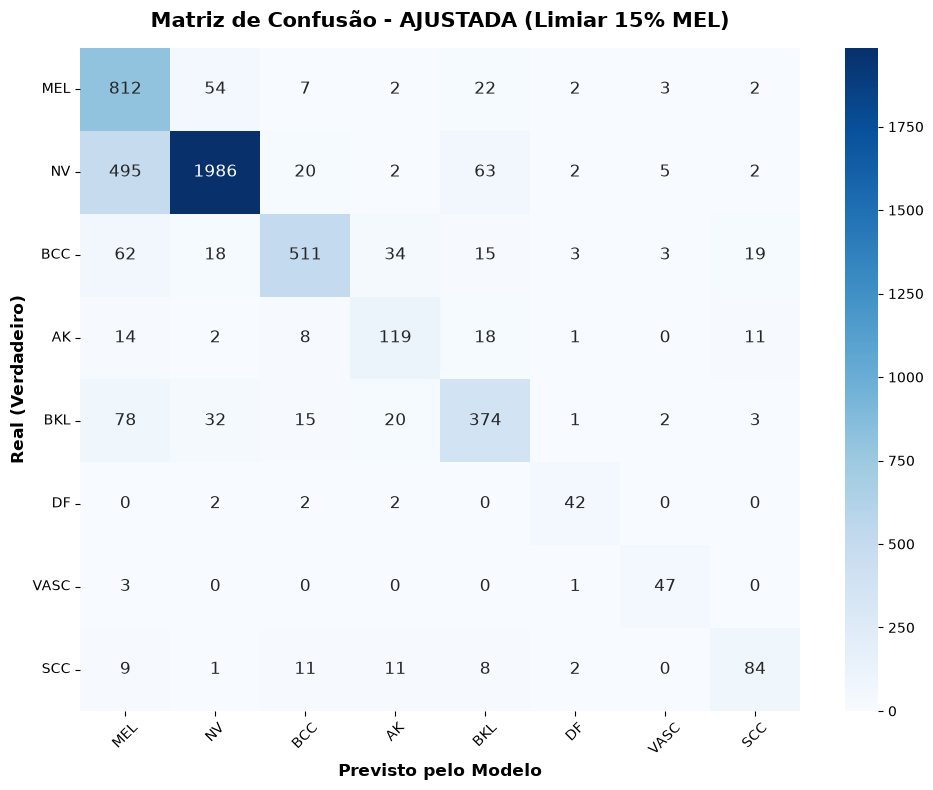

In [43]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Configurações e Carregamento do Modelo
caminho_modelo = 'isic_efficientnet_melhor.pth'
class_names = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
indice_mel = class_names.index('MEL')
limiar_mel = 0.15 # 15%

model = models.efficientnet_b3(weights=None) # Ajustado para B3
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(class_names))

# Carrega os pesos
model.load_state_dict(torch.load(caminho_modelo, map_location=device, weights_only=False))
model = model.to(device)
model.eval()

# 2. Listas para guardar as previsões e os rótulos reais
todos_rotulos = []
previsoes_base = []      # Sem o limiar
previsoes_ajustadas = [] # Com o limiar de 15%

print("Processando imagens de validação. Isso pode levar alguns minutos...")

# 3. Fazendo previsões no val_loader
with torch.no_grad():
    for images, labels in val_loader: # Certifique-se de que o val_loader está carregado
        images = images.to(device)
        outputs = model(images)
        
        # Converte para probabilidades
        probabilidades = F.softmax(outputs, dim=1)
        
        # --- PREVISÃO BASE (Padrão) ---
        prev_base = outputs.argmax(dim=1)
        
        # --- PREVISÃO AJUSTADA (Limiar 15% p/ MEL) ---
        prev_ajustada = prev_base.clone()
        mascara_mel = probabilidades[:, indice_mel] >= limiar_mel
        prev_ajustada[mascara_mel] = indice_mel # Força a classe MEL se for >= 15%
        
        # Move para a CPU e salva nas listas
        todos_rotulos.extend(labels.cpu().numpy())
        previsoes_base.extend(prev_base.cpu().numpy())
        previsoes_ajustadas.extend(prev_ajustada.cpu().numpy())

# 4. Função para desenhar a Matriz de Confusão
def plotar_matriz(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 12})
    
    plt.xlabel('Previsto pelo Modelo', fontsize=12, fontweight='bold')
    plt.ylabel('Real (Verdadeiro)', fontsize=12, fontweight='bold')
    plt.title(titulo, fontsize=15, fontweight='bold', pad=15)
    plt.xticks(rotation=45) 
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 5. Gerar e exibir os dois gráficos para comparação
print("\n📊 Exibindo Matriz de Confusão BASE (Sem Limiar)...")
plotar_matriz(todos_rotulos, previsoes_base, 'Matriz de Confusão - BASE (Padrão)')

print("\n📊 Exibindo Matriz de Confusão AJUSTADA (Limiar 15% para MEL)...")
plotar_matriz(todos_rotulos, previsoes_ajustadas, f'Matriz de Confusão - AJUSTADA (Limiar {limiar_mel*100:.0f}% MEL)')